# 01 Data QA — PVDAQ system 9069 (Simon Solar Farm, GA)

Goal of Phase 1: decide whether 9069 is usable, on which period and with which sensors, and produce a clean dataset. Configuration: `configs/system_9069.yaml`.

Sections:
1. Data coverage and sensor availability (full period, point sampling)
2. Sample checks: time zone, clear-day profiles, measured vs modelled POA (fixed vs tracker), sensor agreement — *to be added*

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Run from the project root so that `src` imports and relative paths in the config work.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import pandas as pd

from src import coverage as cv
from src.config import load_config
from src.plots import availability_heatmap

config = load_config("configs/system_9069.yaml")

## 1. Data coverage and sensor availability

**Method.** Point sampling instead of a full download: ~20 single-row reads per month per file via HTTP byte ranges (≈ 23 MB of traffic instead of ≈ 2.4 GB of CSV); each read returns a snapshot of all channels at one timestamp. Daylight = sun elevation > 15°, so that a 1-hour time-zone error cannot move a snapshot into the night. With ~9 daylight snapshots per month the availability estimate is accurate to about **±15 percentage points**.

Details: *valid* = not empty and not a logger placeholder (≤ −250, e.g. −297, −300). Gaps are found from time jumps between neighbouring snapshots; gaps shorter than ~3 days may be missed. Meter and irradiance files use stratified random offsets (a fixed step of ~25 h aliased with the daily cycle); electrical_ac and environment were sampled with a fixed step of ~32 h, which shifts the time of day by 8 h per snapshot and does not alias. All results below are read from the local cache (`data/processed/9069_coverage/`), no network access.

In [2]:
samples, gaps = cv.load_coverage(config)
table, n_daylight = cv.availability_table(samples, config)

months = pd.period_range("2016-02", "2023-11", freq="M")
table = table.reindex(columns=months)
table.index = [cv.short_label(c) for c in table.index]
n_daylight = n_daylight.reindex(months)
n_daylight.describe().round(1)

,electrical_ac,environment,irradiance,meter
count,90.0,89.0,91.0,78.0
mean,8.4,8.5,8.9,9.7
std,2.6,3.0,5.0,4.2
min,1.0,2.0,1.0,1.0
25%,7.0,7.0,4.5,7.0
50%,9.0,9.0,9.0,10.0
75%,10.0,11.0,13.0,12.0
max,14.0,15.0,24.0,20.0


Gaps longer than 1 day (no rows in the file):

In [3]:
gaps.sort_values(["last_before", "file"]).reset_index(drop=True).head(25)

,file,last_before,first_after,days
0,irradiance,2016-03-13 01:55:00,2016-03-15 11:45:00,2.4
1,meter,2016-04-28 07:15:00,2016-05-04 16:30:00,6.4
2,electrical_ac,2017-02-06 21:15:00,2017-05-13 07:30:00,95.4
3,environment,2017-02-06 21:15:00,2017-05-13 03:25:00,95.3
4,irradiance,2017-02-06 21:15:00,2017-05-13 03:25:00,95.3
5,meter,2017-02-06 21:15:00,2017-05-13 10:35:00,95.6
6,electrical_ac,2017-08-09 07:25:00,2017-08-18 21:00:00,9.6
7,environment,2017-08-09 07:25:00,2017-08-18 20:25:00,9.5
8,irradiance,2017-08-09 07:25:00,2017-08-18 20:25:00,9.5
9,meter,2017-08-09 07:25:00,2017-08-18 21:50:00,9.6


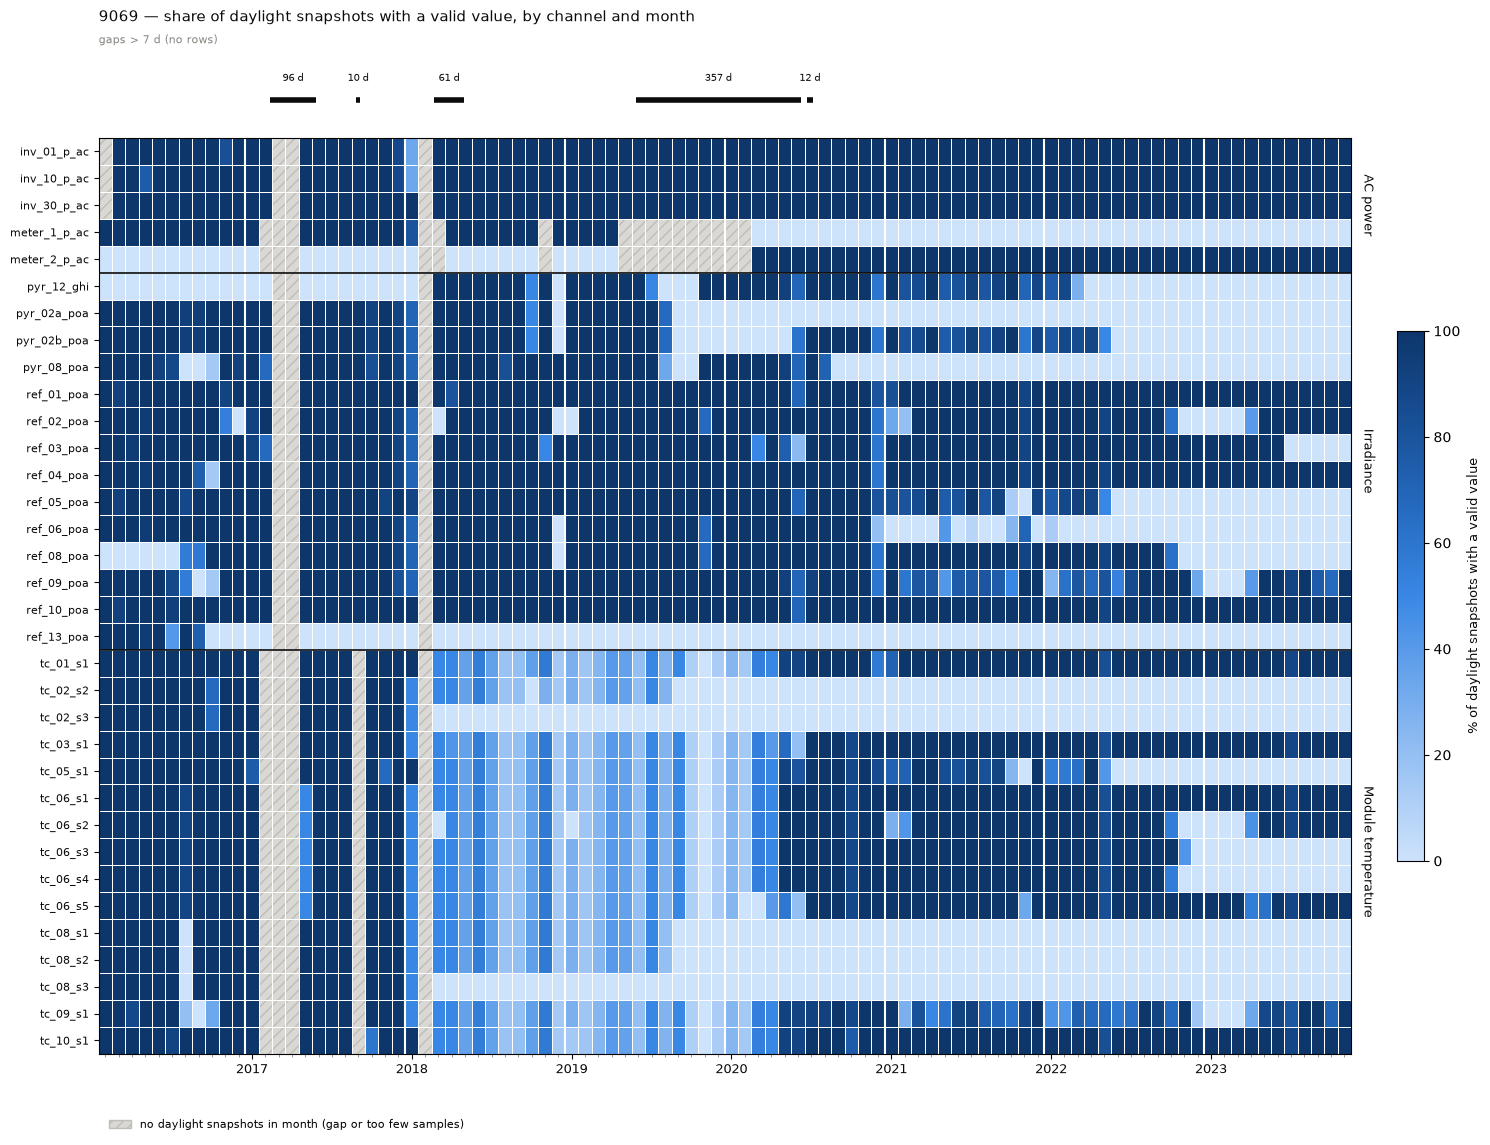

In [4]:
groups = [
    ("AC power", ["inv_01_p_ac", "inv_10_p_ac", "inv_30_p_ac", "meter_1_p_ac", "meter_2_p_ac"]),
    ("Irradiance", ["pyr_12_ghi"] + sorted(l for l in table.index if l.endswith("_poa"))),
    ("Module temperature", sorted(l for l in table.index if l.startswith("tc_"))),
]
fig = availability_heatmap(
    table, groups, gaps,
    title="9069 — share of daylight snapshots with a valid value, by channel and month",
)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/figures/9069_data_coverage.png", dpi=130, bbox_inches="tight")

Yearly mean availability (%), for a compact overview:

In [5]:
table.T.groupby(table.columns.year).mean().T.round(0)

,2016,2017,2018,2019,2020,2021,2022,2023
inv_01_p_ac,98.0,99.0,94.0,100.0,100.0,100.0,100.0,100.0
inv_10_p_ac,98.0,99.0,94.0,100.0,100.0,100.0,100.0,100.0
inv_30_p_ac,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
tc_01_s1,100.0,100.0,43.0,26.0,74.0,98.0,99.0,99.0
tc_02_s2,97.0,100.0,33.0,20.0,0.0,0.0,0.0,0.0
tc_02_s3,97.0,100.0,5.0,0.0,0.0,0.0,0.0,0.0
tc_03_s1,100.0,100.0,38.0,26.0,67.0,100.0,99.0,99.0
tc_05_s1,100.0,93.0,43.0,26.0,74.0,75.0,27.0,0.0
tc_06_s1,99.0,94.0,39.0,26.0,78.0,100.0,99.0,99.0
tc_06_s2,99.0,94.0,34.0,24.0,78.0,89.0,78.0,67.0


### Observations

- **Gaps common to all files:** 2017-02-06 → 2017-05-13 (95 d), 2017-08-09 → 2017-08-18 (10 d), 2018-01-26 → 2018-03-28 (60 d).
- **Meter:** meter 1 reports 2016-02 … 2019-04, then a 357-day gap in the meter file (2019-04-04 → 2020-03-26); from 2020-03 only meter 2 reports. Whether both are the same plant revenue meter is an assumption, to be verified by magnitude.
- **Inverters 01 / 10 / 30:** close to 100 % outside the common gaps.
- **Module temperature:** all thermocouples are intermittent from 2018-03 to 2020-04 (same pattern on every sensor → likely a logger-level problem); from 2020-05 thermocouples 01, 03, 06 s1 and 10 are ≥ 90 %. Thermocouples 02 and 08 are dead from 2020.
- **POA:** reference cells 01, 04 and 10 are ≥ 90 % in almost every month. Class-A pyranometers (02A, 02B, 08) stop between 2020 and 2022; GHI (pyranometer 12) is missing in 2016–2017 and mostly in 2022–2023.
- Irradiance is logged at 15-min steps in 2019 (found in step 0), hence fewer snapshots.

Choice of the analysis period: pending (see candidates).